# Chương 3 — Toán cần thiết cho học máy

Notebook đi kèm giáo trình **Học máy cơ bản với Python** (Lê Nhật Tùng).

**Cách dùng trên Google Colab**

1. Mở <https://colab.research.google.com> → **File** → **Upload notebook** → chọn file này
   (hoặc mở từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chạy lần lượt từng ô từ trên xuống bằng **Shift + Enter**. Các ô sau dùng lại biến của ô trước.
3. Gặp lỗi lạ: **Runtime → Restart session and run all**.

Mỗi ô mã bắt đầu bằng dòng `# ô ten_o` — đó là tên ô in ở đầu mỗi khung mã trong sách,
giúp bạn đối chiếu với giáo trình. Kết quả bên dưới mỗi ô là kết quả chạy mẫu; máy bạn có thể
khác rất nhỏ ở chữ số thập phân cuối nếu phiên bản thư viện khác.

> Hãy **tự gõ lại mã** vào một notebook trống trước khi xem lời giải ở đây — đó là cách học nhanh nhất.


In [1]:
# ô import_thu_vien
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 85)
np.set_printoptions(suppress=True)       # không in số dạng 1.2e-05

## 3.2 Vector

In [2]:
# ô vec_co_ban
a = np.array([3, 1])
b = np.array([1, 2])
print("a + b   =", a + b)
print("2 * a   =", 2 * a)
print("a - b   =", a - b)
print("||a||   =", np.sqrt(np.sum(a ** 2)))     # độ dài theo công thức
print("||a||   =", np.linalg.norm(a))            # hàm có sẵn của NumPy

a + b   = [4 3]
2 * a   = [6 2]
a - b   = [ 2 -1]
||a||   = 3.1622776601683795
||a||   = 3.1622776601683795


In [3]:
# ô vec_khoang_cach
hoa_1 = np.array([5.1, 3.5, 1.4, 0.2])     # bông hoa số 1 của Iris (setosa)
hoa_2 = np.array([7.0, 3.2, 4.7, 1.4])     # bông hoa số 51 (versicolor)
hieu = hoa_1 - hoa_2
print("Hiệu từng thành phần :", hieu.round(2))
print("Bình phương          :", (hieu ** 2).round(2))
print("Tổng bình phương     :", round(np.sum(hieu ** 2), 2))
print("Khoảng cách Euclid   :", round(np.sqrt(np.sum(hieu ** 2)), 4))
print("Dùng np.linalg.norm  :", round(np.linalg.norm(hoa_1 - hoa_2), 4))

Hiệu từng thành phần : [-1.9  0.3 -3.3 -1.2]
Bình phương          : [ 3.61  0.09 10.89  1.44]
Tổng bình phương     : 16.03
Khoảng cách Euclid   : 4.0037
Dùng np.linalg.norm  : 4.0037


In [4]:
# ô vec_dot
so_luong = np.array([2, 3, 1])           # 2 bút, 3 vở, 1 thước
don_gia = np.array([5, 12, 8])           # nghìn đồng
print("Tổng tiền:", np.dot(so_luong, don_gia), "nghìn đồng")
print("Cách viết khác (@):", so_luong @ don_gia)

Tổng tiền: 54 nghìn đồng
Cách viết khác (@): 54


In [5]:
# ô vec_cosine
def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

# Số lần xuất hiện các từ ["bóng đá", "bàn thắng", "cổ phiếu"] trong 3 bài báo
bai_1 = np.array([5, 3, 0])
bai_2 = np.array([10, 7, 1])
bai_3 = np.array([0, 1, 6])
print("cos(bài 1, bài 2) =", round(cosine(bai_1, bai_2), 4))
print("cos(bài 1, bài 3) =", round(cosine(bai_1, bai_3), 4))

cos(bài 1, bài 2) = 0.9942
cos(bài 1, bài 3) = 0.0846


## 3.3 Ma trận

In [6]:
# ô mat_tao
X = np.array([[50, 2],          # căn nhà 1: 50 m², 2 phòng ngủ
              [80, 3],          # căn nhà 2
              [120, 4]])        # căn nhà 3
print("X =\n", X)
print("X.shape   =", X.shape)
print("X.T =\n", X.T)            # chuyển vị: dòng thành cột
print("X.T.shape =", X.T.shape)

X =
 [[ 50   2]
 [ 80   3]
 [120   4]]
X.shape   = (3, 2)
X.T =
 [[ 50  80 120]
 [  2   3   4]]
X.T.shape = (2, 3)


In [7]:
# ô mat_nhan_vector
w = np.array([0.03, 0.2])        # trọng số: 0,03 tỷ/m², 0,2 tỷ/phòng ngủ
b = 0.5                          # giá "nền" 0,5 tỷ
gia_du_doan = X @ w + b          # dự đoán cho cả 3 căn trong một phép tính
print("X @ w     =", X @ w)
print("X @ w + b =", gia_du_doan)

X @ w     = [1.9 3.  4.4]
X @ w + b = [2.4 3.5 4.9]


In [8]:
# ô mat_nhan_mat
A = np.array([[1, 2],
              [3, 4],
              [5, 6]])           # 3 x 2
B = np.array([[1, 0, 2],
              [0, 1, 1]])        # 2 x 3
C = A @ B                        # (3 x 2) @ (2 x 3) -> 3 x 3
print("C =\n", C)
print("C.shape =", C.shape)

C =
 [[ 1  2  4]
 [ 3  4 10]
 [ 5  6 16]]
C.shape = (3, 3)


## 3.4 Đạo hàm và gradient

In [9]:
# ô dao_ham_so
def f(x):
    return x ** 2

def dao_ham_xap_xi(f, x, h=1e-5):
    """Độ dốc của f tại x, xấp xỉ bằng (f(x+h) - f(x)) / h với h rất nhỏ."""
    return (f(x + h) - f(x)) / h

for x in [-2, 0, 1, 3]:
    print(f"x = {x:2d}:  xấp xỉ = {dao_ham_xap_xi(f, x):8.4f}   công thức 2x = {2 * x}")

x = -2:  xấp xỉ =  -4.0000   công thức 2x = -4
x =  0:  xấp xỉ =   0.0000   công thức 2x = 0
x =  1:  xấp xỉ =   2.0000   công thức 2x = 2
x =  3:  xấp xỉ =   6.0000   công thức 2x = 6


In [10]:
# ô gd_tay
def f(x):
    return (x - 3) ** 2          # hàm cần tìm cực tiểu, cực tiểu tại x = 3

def df(x):
    return 2 * (x - 3)           # đạo hàm của f

x = 0.0                          # điểm xuất phát
eta = 0.1                        # tốc độ học (learning rate)
print(" bước       x      f(x)    f'(x)")
for buoc in range(26):
    if buoc <= 5 or buoc % 5 == 0:
        print(f"{buoc:5d}  {x:7.4f}  {f(x):8.4f}  {df(x):7.4f}")
    x = x - eta * df(x)          # cập nhật: đi ngược hướng đạo hàm

 bước       x      f(x)    f'(x)
    0   0.0000    9.0000  -6.0000
    1   0.6000    5.7600  -4.8000
    2   1.0800    3.6864  -3.8400
    3   1.4640    2.3593  -3.0720
    4   1.7712    1.5099  -2.4576
    5   2.0170    0.9664  -1.9661
   10   2.6779    0.1038  -0.6442
   15   2.8944    0.0111  -0.2111
   20   2.9654    0.0012  -0.0692
   25   2.9887    0.0001  -0.0227


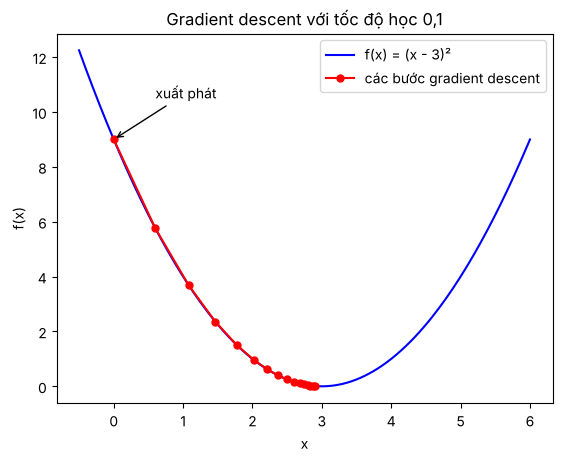

In [11]:
# ô gd_hinh
x, eta, duong_di = 0.0, 0.1, [0.0]
for _ in range(15):
    x = x - eta * df(x)
    duong_di.append(x)
duong_di = np.array(duong_di)
xs = np.linspace(-0.5, 6, 200)
plt.plot(xs, f(xs), "b-", label="f(x) = (x - 3)²")
plt.plot(duong_di, f(duong_di), "ro-", ms=5, label="các bước gradient descent")
plt.annotate("xuất phát", (0, 9), xytext=(0.6, 10.5), arrowprops=dict(arrowstyle="->"))
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Gradient descent với tốc độ học 0,1")
plt.legend()
plt.show()

In [12]:
# ô gd_2bien
def g(w):                        # hàm hai biến g(w1, w2) = w1² + 3·w2²
    return w[0] ** 2 + 3 * w[1] ** 2

def grad_g(w):                   # gradient = (đạo hàm riêng theo w1, theo w2)
    return np.array([2 * w[0], 6 * w[1]])

w = np.array([4.0, 2.0])
for buoc in range(1, 31):
    w = w - 0.1 * grad_g(w)
    if buoc in (1, 2, 3, 10, 20, 30):
        print(f"bước {buoc:2d}: w = {w.round(4)}, g(w) = {g(w):.6f}")

bước  1: w = [3.2 0.8], g(w) = 12.160000
bước  2: w = [2.56 0.32], g(w) = 6.860800
bước  3: w = [2.048 0.128], g(w) = 4.243456
bước 10: w = [0.4295 0.0002], g(w) = 0.184468
bước 20: w = [0.0461 0.    ], g(w) = 0.002127
bước 30: w = [0.005 0.   ], g(w) = 0.000025


## 3.5 Thống kê mô tả

In [13]:
# ô tk_trung_tam
diem = np.array([5, 7, 7, 8, 10])
print("Trung bình :", diem.mean())
print("Trung vị   :", np.median(diem))
gia_tri, so_lan = np.unique(diem, return_counts=True)
print("Yếu vị     :", gia_tri[np.argmax(so_lan)])

Trung bình : 7.4
Trung vị   : 7.0
Yếu vị     : 7


In [14]:
# ô tk_ngoai_lai
luong = np.array([8, 9, 10, 10, 11, 12, 100])     # triệu đồng/tháng; có 1 giám đốc
print("Trung bình:", round(luong.mean(), 2), "   Trung vị:", np.median(luong))

Trung bình: 22.86    Trung vị: 10.0


In [15]:
# ô tk_phan_tan
diem = np.array([5, 7, 7, 8, 10])
print("Phương sai (chia n)      :", round(diem.var(), 4))
print("Độ lệch chuẩn (chia n)   :", round(diem.std(), 4))
print("Độ lệch chuẩn (chia n-1) :", round(diem.std(ddof=1), 4))
print("pandas .std() mặc định   :", round(pd.Series(diem).std(), 4))

Phương sai (chia n)      : 2.64
Độ lệch chuẩn (chia n)   : 1.6248
Độ lệch chuẩn (chia n-1) : 1.8166
pandas .std() mặc định   : 1.8166


In [16]:
# ô tk_phan_vi
du_lieu = np.array([2, 4, 4, 5, 6, 7, 8, 9, 12, 30])
q1, q2, q3 = np.percentile(du_lieu, [25, 50, 75])
iqr = q3 - q1
print("Q1 =", q1, " Q2 (trung vị) =", q2, " Q3 =", q3, " IQR =", iqr)
can_duoi, can_tren = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("Khoảng bình thường: [", can_duoi, ",", can_tren, "]")
print("Giá trị ngoại lai :", du_lieu[(du_lieu < can_duoi) | (du_lieu > can_tren)])

Q1 = 4.25  Q2 (trung vị) = 6.5  Q3 = 8.75  IQR = 4.5
Khoảng bình thường: [ -2.5 , 15.5 ]
Giá trị ngoại lai : [30]


In [17]:
# ô tk_tuong_quan
gio_hoc = np.array([2, 4, 6, 8, 10])
diem_thi = np.array([4, 5, 7, 8, 9])
r = np.corrcoef(gio_hoc, diem_thi)[0, 1]
print("Hệ số tương quan r =", round(r, 4))

Hệ số tương quan r = 0.9912


## 3.6 Xác suất

In [18]:
# ô xs_bayes
p_benh = 0.01                    # 1% dân số mắc bệnh
p_duong_neu_benh = 0.95          # xét nghiệm phát hiện đúng 95% người bệnh
p_duong_neu_khoe = 0.05          # 5% người khỏe bị báo nhầm là dương tính
p_duong = p_duong_neu_benh * p_benh + p_duong_neu_khoe * (1 - p_benh)
p_benh_neu_duong = p_duong_neu_benh * p_benh / p_duong
print(f"P(dương tính)          = {p_duong:.4f}")
print(f"P(bệnh | dương tính)   = {p_benh_neu_duong:.4f}")

P(dương tính)          = 0.0590
P(bệnh | dương tính)   = 0.1610


In [19]:
# ô xs_chuan
rng = np.random.default_rng(42)
chieu_cao = rng.normal(loc=165, scale=7, size=10_000)   # 10.000 người, TB 165cm, ĐLC 7cm
tb, dlc = chieu_cao.mean(), chieu_cao.std()
print(f"Trung bình = {tb:.2f} cm, độ lệch chuẩn = {dlc:.2f} cm")
for k in (1, 2, 3):
    ti_le = np.mean(np.abs(chieu_cao - tb) <= k * dlc)
    print(f"Tỉ lệ nằm trong ±{k} độ lệch chuẩn: {ti_le:.2%}")

Trung bình = 164.93 cm, độ lệch chuẩn = 7.04 cm
Tỉ lệ nằm trong ±1 độ lệch chuẩn: 68.19%
Tỉ lệ nằm trong ±2 độ lệch chuẩn: 95.54%
Tỉ lệ nằm trong ±3 độ lệch chuẩn: 99.69%


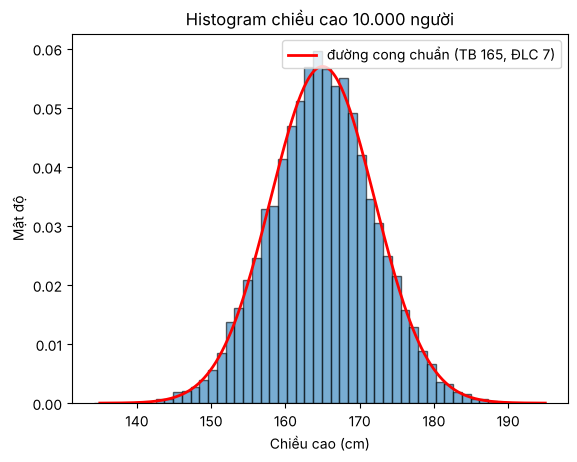

In [20]:
# ô xs_chuan_hinh
plt.hist(chieu_cao, bins=50, density=True, color="tab:blue", alpha=0.6, edgecolor="k")
xs = np.linspace(135, 195, 300)
mat_do = np.exp(-(xs - 165) ** 2 / (2 * 7 ** 2)) / (7 * np.sqrt(2 * np.pi))
plt.plot(xs, mat_do, "r-", lw=2, label="đường cong chuẩn (TB 165, ĐLC 7)")
plt.xlabel("Chiều cao (cm)"); plt.ylabel("Mật độ")
plt.title("Histogram chiều cao 10.000 người")
plt.legend()
plt.show()

## Thực hành 3.1: Toán trên dữ liệu Iris

In [21]:
# ô lab_buoc1
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
X = iris.data.to_numpy()                 # mảng NumPy 150 x 4
y = iris.target.to_numpy()
print("Trung bình từng đặc trưng :", X.mean(axis=0).round(3))
print("Độ lệch chuẩn từng đặc trưng:", X.std(axis=0).round(3))

Trung bình từng đặc trưng : [5.843 3.057 3.758 1.199]
Độ lệch chuẩn từng đặc trưng: [0.825 0.434 1.759 0.76 ]


In [22]:
# ô lab_buoc2
hoa_moi = np.array([5.9, 3.0, 4.9, 1.7])
khoang_cach = np.sqrt(((X - hoa_moi) ** 2).sum(axis=1))   # 150 khoảng cách
gan_nhat = np.argsort(khoang_cach)[:5]                    # vị trí 5 bông gần nhất
for i in gan_nhat:
    print(f"Bông số {i:3d}: khoảng cách = {khoang_cach[i]:.4f}, "
          f"loài = {iris.target_names[y[i]]}")

Bông số 138: khoảng cách = 0.1732, loài = virginica
Bông số 127: khoảng cách = 0.2236, loài = virginica
Bông số 149: khoảng cách = 0.2236, loài = virginica
Bông số  70: khoảng cách = 0.2449, loài = versicolor
Bông số  83: khoảng cách = 0.3873, loài = versicolor


In [23]:
# ô lab_buoc3
tq = iris.data.corr().round(3)
tq.columns = ["dai_dai", "rong_dai", "dai_canh", "rong_canh"]
tq.index = tq.columns
print(tq)

           dai_dai  rong_dai  dai_canh  rong_canh
dai_dai      1.000    -0.118     0.872      0.818
rong_dai    -0.118     1.000    -0.428     -0.366
dai_canh     0.872    -0.428     1.000      0.963
rong_canh    0.818    -0.366     0.963      1.000


## Bài tập tự làm

Mức độ: ⭐ cơ bản, ⭐⭐ nâng cao, ⭐⭐⭐ thử thách. Viết lời giải vào ô mã trống ngay dưới mỗi bài.

**Bài 3.1.** ⭐ Cho $\mathbf{a} = (2, -1, 3)$, $\mathbf{b} = (1, 4, 0)$. Tính tay $\mathbf{a} + \mathbf{b}$, $3\mathbf{a} - \mathbf{b}$, $\|\mathbf{a}\|$, $\mathbf{a} \cdot \mathbf{b}$ và khoảng cách giữa $\mathbf{a}$ và $\mathbf{b}$. Kiểm tra lại bằng NumPy.

In [ ]:
# Lời giải Bài 3.1


**Bài 3.2.** ⭐ Một cửa hàng bán 3 sản phẩm với đơn giá $(20, 35, 50)$ nghìn đồng. Ba khách hàng mua số lượng lần lượt là $(1, 2, 0)$, $(0, 1, 3)$ và $(4, 0, 1)$. Viết ma trận số lượng và tính số tiền mỗi khách phải trả bằng **một** phép nhân ma trận với vector.

In [ ]:
# Lời giải Bài 3.2


**Bài 3.3.** ⭐ Tính tay trung bình, trung vị, phương sai (chia $n$) và độ lệch chuẩn của dãy $3, 6, 6, 7, 8, 12$. Kiểm tra bằng NumPy.

In [ ]:
# Lời giải Bài 3.3


**Bài 3.4.** ⭐ Tính đạo hàm của các hàm: $f(x) = 4x^2 - 3x + 7$; $g(x) = (x + 2)^2$; $h(x) = x^3 - 6x$. Tìm $x$ để $f'(x) = 0$.

In [ ]:
# Lời giải Bài 3.4


**Bài 3.5.** ⭐⭐ Thực hiện tay 3 bước gradient descent cho $f(x) = x^2 - 4x + 1$ với $x_0 = 0$ và $\eta = 0,25$. Sau đó viết chương trình chạy 30 bước và so sánh với cực tiểu đúng (tìm bằng cách giải $f'(x) = 0$).

In [ ]:
# Lời giải Bài 3.5


**Bài 3.6.** ⭐⭐ Với hàm $g(w_1, w_2) = (w_1 - 1)^2 + 2(w_2 + 2)^2$: (a) tính các đạo hàm riêng; (b) cho biết điểm cực tiểu; (c) viết chương trình gradient descent từ $(0, 0)$ với $\eta = 0,1$ và in vị trí sau 50 bước.

In [ ]:
# Lời giải Bài 3.6


**Bài 3.7.** ⭐⭐ Với dữ liệu tips (Chương 2), dùng quy tắc 1,5 IQR để đếm số hóa đơn có `total_bill` là ngoại lai. Vẽ boxplot để kiểm tra trực quan.

In [ ]:
# Lời giải Bài 3.7


**Bài 3.8.** ⭐⭐ Một bộ lọc thư rác nhận thấy: 40% thư là thư rác; 60% thư rác chứa chữ “miễn phí”; chỉ 5% thư thường chứa chữ “miễn phí”. Dùng định lý Bayes tính xác suất một thư là thư rác khi nó chứa chữ “miễn phí”. (Gợi ý: hình dung 1 000 thư như ví dụ xét nghiệm.)

In [ ]:
# Lời giải Bài 3.8


**Bài 3.9.** ⭐⭐⭐ Viết hàm `gradient_descent(df, x0, eta, so_buoc)` tổng quát, nhận hàm đạo hàm `df` làm tham số và trả về danh sách các vị trí đã đi qua. Dùng hàm này để tái tạo Hình 3.6 (bốn tốc độ học), và tìm bằng thực nghiệm giá trị $\eta$ lớn nhất mà thuật toán vẫn hội tụ với $f(x) = (x - 3)^2$. Giải thích kết quả bằng cách viết $x_{\text{mới}} - 3$ theo $x_{\text{cũ}} - 3$.

In [ ]:
# Lời giải Bài 3.9
